# ¿Describen las matrices anuales a una cohorte? Pruebas de Markov, inercia y pruebas de estabilidad del BCE

**Pregunta:** ¿Describe una sola matriz a un año cómo se mueven las calificaciones de S&P, y qué prueba detecta qué desvío del modelo de Markov: una matriz que cambia de un año a otro, o la inercia de las calificaciones?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 02 y 03 de este tema (la matriz agrupada y los generadores)
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook puedes:

- probar si una matriz a un año es la misma cada año (homogeneidad en el tiempo) y si cada año concuerda con la matriz agrupada, y leer un estadístico que es once veces sus grados de libertad;
- calcular el ancho de banda ponderado de la matriz y las pruebas z de migración del BCE sobre cada cohorte, y los índices de movilidad junto a la tasa de incumplimiento de los grados especulativos;
- correr la prueba de orden y la prueba de inercia sobre trayectorias de calificación, y ver en un conjunto de datos con inercia plantada que la prueba de homogeneidad no la detecta;
- leer el estudio de potencia de 200 conjuntos de datos: cuán seguido rechaza cada prueba a medida que crece la inercia o el estrés;
- comparar la frecuencia de incumplimiento a cinco años que vivió una cohorte con lo que proyectan las matrices a un año, y decir qué tres cosas distintas cuentan los números.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.transitions import estimators, mobility
from riskvalidation.transitions.em import em_generator
from riskvalidation.validation import rating_system, transitions as tests
from scipy.linalg import expm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cinco archivos versionados del caso C04, de la publicación CEREP de ESMA (clase de licencia `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/):

- `data/derived/C04/sp.json`: las tablas de conteos anuales y semestrales de S&P, la matriz agrupada, y lo que el caso calculó de ellas: `outputs.homogeneity`, `outputs.ecb`, `outputs.mobility`, `outputs.lifetime`.
- `data/derived/C04/models-transitions.json`: el generador ajustado a los conteos de S&P, la verdad conocida de los conjuntos simulados.
- `data/derived/C04/momentum.json` y `data/derived/C04/cycle.json`: dos estudios de simulación versionados de 200 conjuntos con semilla por peldaño, uno con una intensidad de bajada autoexcitada (inercia) de fuerza creciente, otro con las tasas de bajada multiplicadas por un factor en el tercer año (un régimen de estrés).

CEREP tiene conteos, nunca trayectorias individuales, así que los datos reales pueden correr las pruebas que solo necesitan tablas de conteos (homogeneidad, las pruebas del BCE) y no pueden correr la prueba de orden (necesita el estado en tres fechas consecutivas de cada deudor) ni la de inercia (necesita la trayectoria). Esas dos corren sobre trayectorias simuladas, sacadas aquí del generador versionado.

La celda siguiente carga los archivos y construye las tablas cuadradas de conteos que reciben las pruebas.

In [2]:
# Cargar los artefactos (el notebook está tres carpetas bajo la raíz) y hacer cuadradas las tablas
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
load = lambda name: json.loads((C04 / name).read_text(encoding="utf-8"))
sp, models = load("sp.json"), load("models-transitions.json")
power_m, power_c = load("momentum.json"), load("cycle.json")
out = sp["outputs"]
grades, states = out["grades"], out["states"]
cohorts = out["cohorts"]
annual = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in cohorts]
semesters = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in out["semesters"]]

print("tablas anuales:", len(annual), "| tablas semestrales:", len(semesters))

tablas anuales: 26 | tablas semestrales: 32


## Método

### Paso 1: ¿es la matriz la misma cada año?

Anderson y Goodman (1957) prueban la homogeneidad en el tiempo: si las probabilidades de transición $p_{ij}(t)$ son las mismas en todo período frente a la $\hat p_{ij}$ agrupada. Su forma chi-cuadrado (ecuación 3.8) suma, sobre los estados iniciales $i$ (la fila absorbente de incumplimiento no aporta información), los períodos $t$ y los estados finales $j$,

$$\chi^2 = \sum_i \sum_{t, j} n_i(t-1)\,\frac{\bigl(\hat p_{ij}(t) - \hat p_{ij}\bigr)^2}{\hat p_{ij}}$$

con $n_i(t-1)$ las calificaciones que empezaron el período $t$ en $i$. Bajo la nula es asintóticamente chi-cuadrado con $(T-1)(m-1)$ grados de libertad por fila, donde se quitan las celdas y los períodos vacíos (la convención del motor). La forma de razón de verosimilitud (3.5) también está en el resultado. El `rating_time_homogeneity` del motor recibe la pila de tablas de conteos.

La celda siguiente lo llama sobre las 26 tablas anuales y sobre las 32 tablas semestrales e imprime cada estadístico frente a sus grados de libertad: bajo la nula los dos son del mismo tamaño. Una segunda tabla reparte el estadístico anual por grado inicial.

In [3]:
# Homogeneidad en el tiempo en las 26 tablas anuales y las 32 semestrales, y la contribución de cada grado
hom_annual = tests.rating_time_homogeneity(annual, model_id="STPGB", segment="annual")
hom_semesters = tests.rating_time_homogeneity(semesters, model_id="STPGB", segment="semesters")

for label, r in (("anual", hom_annual), ("semestres", hom_semesters)):
    dof = r.extras["dof"]
    print(f"{label:11s} chi2 = {r.statistic:10.2f} | dof = {dof} | chi2 / dof = {r.statistic / dof:.2f}",
          f"| p = {r.p_value:.3g}")
rows = hom_annual.extras["rows"]
print(f"{'grado':8s}{'chi2':>10s}{'dof':>8s}{'chi2 / dof':>12s}")
for row in rows:
    print(f"{grades[row['row']]:8s}{row['chi2']:10.2f}{row['dof']:8d}{row['chi2'] / row['dof']:12.2f}")

anual       chi2 =   12028.16 | dof = 1075 | chi2 / dof = 11.19 | p = 0
semestres   chi2 =   14248.61 | dof = 899 | chi2 / dof = 15.85 | p = 0
grado         chi2     dof  chi2 / dof
AAA         330.13     100        3.30
AA         5763.16     175       32.93
A          1562.54     175        8.93
BBB        1370.75     175        7.83
BB          971.37     175        5.55
B          1638.98     150       10.93
CCC-C       391.23     125        3.13


La celda siguiente dibuja el chi cuadrado de cada grado inicial sobre sus grados de libertad, con el valor uno que daría la nula.

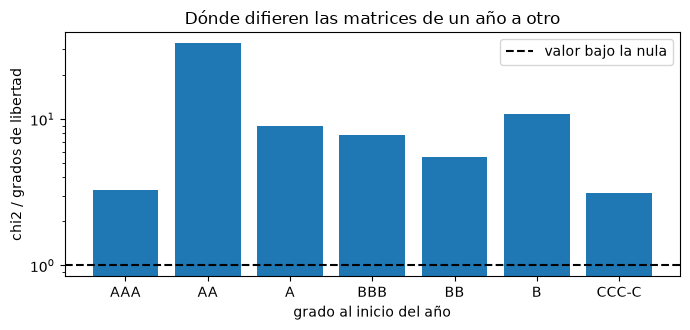

In [4]:
# Dibujar la parte de cada grado del estadístico de homogeneidad por grado de libertad
ratio = [row["chi2"] / row["dof"] for row in rows]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar([grades[row["row"]] for row in rows], ratio, color="tab:blue")
ax.axhline(1.0, color="black", linestyle="--", label="valor bajo la nula")
ax.set_yscale("log")
ax.set_xlabel("grado al inicio del año")
ax.set_ylabel("chi2 / grados de libertad")
ax.set_title("Dónde difieren las matrices de un año a otro")
ax.legend()
fig.tight_layout()
plt.show()

El estadístico está muy por encima de sus grados de libertad, y el valor p queda bajo el menor número que guarda la precisión doble (el motor informa 0). Con unos 170.000 años-calificación la prueba tiene la potencia para ver cualquier diferencia entre años, y la matriz cambia de un año a otro. La figura muestra que todo grado aporta más de lo que permite la nula, AA el que más por grado de libertad (32,93) y CCC-C el que menos (3,13). Lo que la prueba no dice es qué desvío del modelo de Markov produjo el rechazo, un cambio de régimen en el tiempo, la inercia u otra cosa, a lo que el Paso 5 vuelve.

### Paso 2: cada año contra la matriz agrupada

Una segunda lectura pregunta, para cada año por separado, si sus conteos son compatibles con la matriz agrupada como referencia especificada. El `rating_matrix_reference` del motor usa por defecto la razón de verosimilitud $2\sum n_{ij} \log(\hat p_{ij} / p^0_{ij})$ (el análogo de razón de verosimilitud de la ecuación 3.1 de Anderson y Goodman, elegido porque mantuvo su tamaño donde la forma impresa no lo hizo) e informa además todo movimiento que la matriz agrupada llama imposible (un conteo donde la referencia tiene cero).

La celda siguiente primero agrupa las 26 tablas en la matriz de referencia con el motor, luego corre la prueba sobre cada cohorte y cuenta los rechazos al 5% y al 1%.

In [5]:
# Agrupar las tablas en la matriz de referencia y probar cada cohorte anual contra ella
gone = [np.append(np.array(c["withdrawn"], dtype=float), 0.0) for c in cohorts]
P = estimators.pooled_cohort(annual, gone, treatment="exclude")["matrix"]
refs = [tests.rating_matrix_reference(t, P, model_id="STPGB", segment=c["label"]) for t, c in zip(annual, cohorts)]
stat = np.array([r.statistic for r in refs])
dof = np.array([r.extras["dof"] for r in refs])
pvals = np.array([r.p_value for r in refs])
years = [c["label"] for c in cohorts]

print("cohortes rechazadas al 5%:", int((pvals < 0.05).sum()), "de", len(refs), "| al 1%:", int((pvals < 0.01).sum()))
ratio = stat / dof
order = np.argsort(ratio)
print("LR / dof: menor", round(float(ratio[order[0]]), 2), "en", years[order[0]])
print("LR / dof: tres mayores:", [(years[k], round(float(ratio[k]), 2)) for k in order[::-1][:3]])
print("cohortes con un movimiento que la matriz agrupada llama imposible:",
      sum(1 for r in refs if r.extras["impossible_moves"]))

cohortes rechazadas al 5%: 26 de 26 | al 1%: 26
LR / dof: menor 2.27 en 2012
LR / dof: tres mayores: [('2021', 55.27), ('2002', 16.83), ('2020', 13.44)]
cohortes con un movimiento que la matriz agrupada llama imposible: 0


La celda siguiente dibuja el estadístico sobre sus grados de libertad para cada año, y la línea en uno es lo que daría un año sorteado de la matriz agrupada.

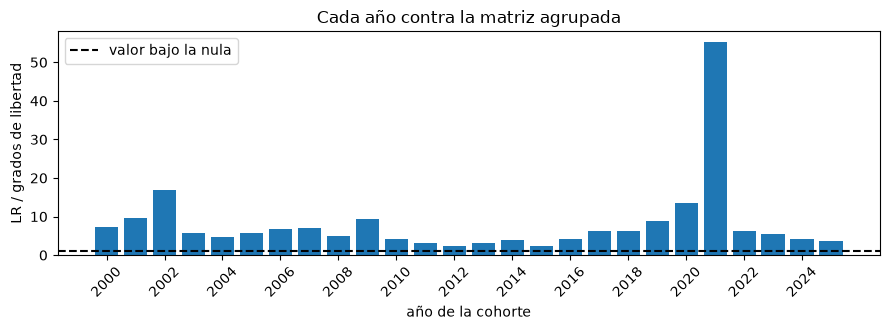

In [6]:
# Dibujar el estadístico de razón de verosimilitud por grado de libertad de cada año contra la matriz agrupada
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(years, stat / dof, color="tab:blue")
ax.axhline(1.0, color="black", linestyle="--", label="valor bajo la nula")
ax.set_xticks(range(0, len(years), 2))
ax.set_xticklabels(years[::2], rotation=45)
ax.set_xlabel("año de la cohorte")
ax.set_ylabel("LR / grados de libertad")
ax.set_title("Cada año contra la matriz agrupada")
ax.legend()
fig.tight_layout()
plt.show()

Cada uno de los 26 años rechaza la matriz agrupada, el menor estadístico (2012, 2,27 por grado de libertad) tanto como el mayor (2021, 55,27). Eso es lo que hace una matriz agrupada sobre varios regímenes a un solo año, y ninguna de las cohortes tiene un movimiento que la matriz agrupada llame imposible, así que los rechazos vienen del tamaño de las frecuencias y no de celdas vacías. La figura muestra que el desvío está lejos de ser uniforme: 2021 destaca, 2002 y 2020 siguen con 16,8 y 13,4, y los demás años quedan bajo 10. Una barra por año no puede separar cuánto de eso es el régimen del año y cuánto la cantidad de calificaciones detrás de cada cohorte.

### Paso 3: las pruebas de estabilidad del BCE sobre cada cohorte

La plantilla de reporte del BCE (BCE, 2019, sección 2.5.5) pide dos cosas a la matriz de migración de un sistema de calificación. El **ancho de banda ponderado de la matriz** (MWB, sección 2.5.5.1) mide cuánto migran las calificaciones: para bajadas (superior) y subidas (inferior), la distancia media de las migraciones ponderada por los deudores, relativa a la mayor distancia posible desde cada grado; 0 cuando nadie migra, 1 en el extremo. Es descriptivo, así que la política por defecto no da luz. Las **pruebas z de migración** (sección 2.5.5.2) verifican que, en cada fila, la frecuencia de moverse no aumenta al alejarse de la diagonal: una prueba z por celda fuera de la diagonal contra su vecina más cercana a la diagonal. El motor agrega un ajuste de Holm entre las celdas e informa el menor valor p ajustado. Ambas se aplican al bloque de transiciones entre los grados vigentes.

La celda siguiente corre ambas sobre el bloque vigente de 7 x 7 de cada cohorte e imprime tres cohortes: la primera, la más móvil y la última.

In [7]:
# MWB y pruebas z de migración sobre el bloque vigente de 7 x 7 de cada cohorte
blocks = [np.array(c["counts"], dtype=float)[:, :7] for c in cohorts]
mwb = [rating_system.rating_mwb(b, model_id="STPGB", segment=c["label"]) for b, c in zip(blocks, cohorts)]
ztest = [rating_system.rating_migration_ztests(b, model_id="STPGB", segment=c["label"])
         for b, c in zip(blocks, cohorts)]
up = np.array([r.extras["mwb_upper"] for r in mwb])
down = np.array([r.extras["mwb_lower"] for r in mwb])
zp = np.array([r.p_value for r in ztest])

print("luz del MWB:", mwb[0].light.value, "| cohortes con p de Holm bajo 0.05:", int((zp < 0.05).sum()))
print(f"{'cohorte':8s}{'MWB sube':>12s}{'MWB baja':>12s}{'p (Holm)':>12s}")
for k in (0, int(up.argmax()), len(up) - 1):
    print(f"{years[k]:8s}{up[k]:12.4f}{down[k]:12.4f}{zp[k]:12.4f}")

luz del MWB: not_evaluated | cohortes con p de Holm bajo 0.05: 2
cohorte     MWB sube    MWB baja    p (Holm)
2000          0.2678      0.2878      0.9946
2001          0.2732      0.2699      0.0099
2025          0.2269      0.2310      1.0000


La celda siguiente dibuja los dos anchos de banda por año, y a su lado el menor valor p ajustado de las pruebas z con la línea de 5%.

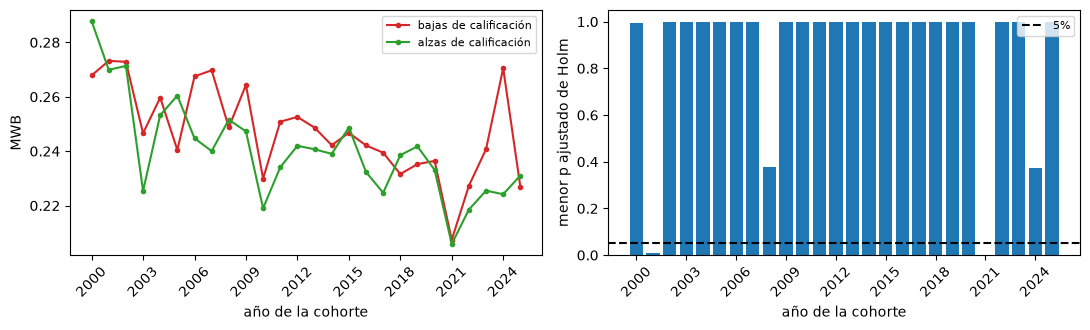

In [8]:
# Dibujar el ancho de banda ponderado por año (izquierda) y el menor p ajustado de Holm de las pruebas z (derecha)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4))
left.plot(years, up, color="tab:red", marker="o", markersize=3, label="bajas de calificación")
left.plot(years, down, color="tab:green", marker="o", markersize=3, label="alzas de calificación")
left.set_xticks(range(0, len(years), 3))
left.set_xticklabels(years[::3], rotation=45)
left.set_xlabel("año de la cohorte")
left.set_ylabel("MWB")
left.legend(fontsize=8)
right.bar(years, zp, color="tab:blue")
right.axhline(0.05, color="black", linestyle="--", label="5%")
right.set_xticks(range(0, len(years), 3))
right.set_xticklabels(years[::3], rotation=45)
right.set_xlabel("año de la cohorte")
right.set_ylabel("menor p ajustado de Holm")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

Los anchos de banda describen cuán lejos migran las calificaciones, y se mueven entre 0,2 y 0,3 sin una tendencia que la política del BCE convierta en una luz: el motor informa el MWB como no evaluado. Las pruebas z hacen una pregunta más aguda, si la frecuencia de moverse crece alguna vez al alejarse de la diagonal, y tras el ajuste de Holm entre celdas solo dos de las 26 cohortes levantan una bandera, 2001 con un menor p de 0,0099 y 2021 con un p cercano a cero. Así que las cohortes pasan las pruebas de estabilidad del BCE que miran la forma de cada matriz, mientras el Paso 1 mostró que las matrices difieren entre sí. Los dos tipos de prueba responden preguntas distintas, y pasar una no despeja la otra.

### Paso 4: cuánto se mueve la matriz, y cuándo

Los índices de movilidad resumen una matriz completa en un número. El `svd_mobility` del motor devuelve el valor singular medio de $P - I$ (el índice de Jafry y Schuermann, 2004) y `trace_mobility` el índice de traza $(n - \mathrm{tr} P)/(n-1)$. Ambos son 0 para una matriz identidad.

La celda siguiente calcula ambos índices sobre la matriz de cada cohorte y sobre la matriz agrupada, y los pone junto a la tasa de incumplimiento de los grados especulativos que guarda el artefacto para cada año.

In [9]:
# Movilidad de la matriz propia de cada cohorte y de la matriz agrupada, junto a la tasa de incumplimiento especulativa
own = [estimators.cohort(t, g, treatment="exclude")["matrix"] for t, g in zip(annual, gone)]
svd = np.array([mobility.svd_mobility(m) for m in own])
trace = np.array([mobility.trace_mobility(m) for m in own])
spec = np.array([np.nan if v is None else v for v in out["mobility"]["spec_default_rate"]], dtype=float)
ok = np.isfinite(spec)

print("matriz agrupada: M_SVD =", round(mobility.svd_mobility(P), 4),
      "| índice de traza =", round(mobility.trace_mobility(P), 4))
print("año más móvil:", years[int(svd.argmax())], round(float(svd.max()), 4),
      "| menos móvil:", years[int(svd.argmin())], round(float(svd.min()), 4))
print("correlación de M_SVD con la tasa de incumplimiento especulativa:",
      round(float(np.corrcoef(svd[ok], spec[ok])[0, 1]), 3))

matriz agrupada: M_SVD = 0.1353 | índice de traza = 0.1372
año más móvil: 2002 0.2189 | menos móvil: 2023 0.0658
correlación de M_SVD con la tasa de incumplimiento especulativa: 0.269


La celda siguiente dibuja los dos índices de movilidad en el eje izquierdo y la tasa de incumplimiento en el derecho.

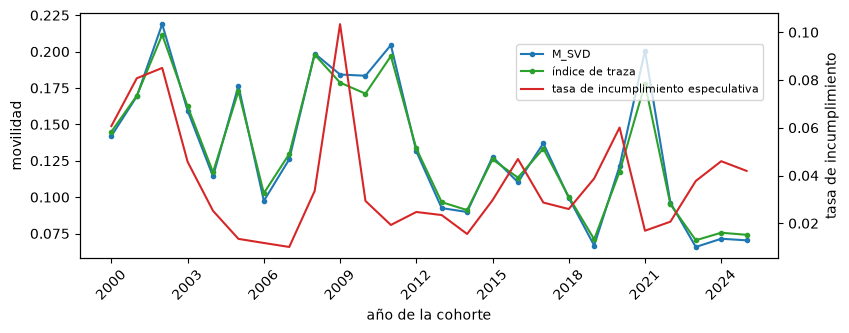

In [10]:
# Dibujar los índices de movilidad y la tasa de incumplimiento especulativa por año
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(years, svd, color="tab:blue", marker="o", markersize=3, label="M_SVD")
ax.plot(years, trace, color="tab:green", marker="o", markersize=3, label="índice de traza")
ax.set_ylabel("movilidad")
ax.set_xlabel("año de la cohorte")
ax.set_xticks(range(0, len(years), 3))
ax.set_xticklabels(years[::3], rotation=45)
twin = ax.twinx()
twin.plot(years, spec, color="tab:red", label="tasa de incumplimiento especulativa")
twin.set_ylabel("tasa de incumplimiento")
fig.legend(loc="upper right", fontsize=8, bbox_to_anchor=(0.9, 0.88))
fig.tight_layout()
plt.show()

La movilidad es alta a comienzos de los 2000, con su máximo en 2002 (M_SVD 0,219), y baja en los años recientes, con su mínimo en 2023 (0,066). La tasa de incumplimiento de los grados especulativos sigue el mismo ciclo, con máximos en 2001 a 2002 y 2009. En los 26 años M_SVD se correlaciona 0,27 con esa tasa: el movimiento y los incumplimientos se relacionan, pero están lejos de ser lo mismo, porque la movilidad cuenta las alzas tanto como las bajas. La figura no puede decir si los años recientes tranquilos son un ciclo calmo o un cambio en la manera de calificar de la agencia, que es lo que una prueba de estabilidad debe mantener separado.

### Paso 5: orden y inercia, sobre trayectorias cuya verdad se conoce

Otras dos desviaciones del modelo de Markov importan en la práctica. La prueba de **orden** (Anderson y Goodman, ecuación 3.12) pregunta si el estado siguiente depende también del anterior y no solo del actual. El valor por defecto del motor agrupa los estados anterior y siguiente por dirección (desde un grado mejor, el mismo, uno peor; hacia uno mejor, el mismo, uno peor), la agrupación sobre la que actúa el momentum. La prueba de **inercia** (dos Reis, Pfeuffer y Smith, 2020) ajusta la intensidad de salida de un grado como $\lambda(t) = q_i(t)\, e^{cZ}$ con $Z = 1$ para un deudor rebajado hasta su grado actual, y prueba $c = 0$ con una razón de verosimilitud.

Ninguna puede correr sobre los conteos de CEREP. La celda siguiente saca dos conjuntos de datos del generador versionado, con semilla y el mismo número de deudores: uno de Markov, otro donde cada rebaja sube la intensidad de nuevas rebajas (inercia de `RatingPaths` con fuerza 0,125 y decaimiento 1 por año, la fuerza con que el estudio versionado recupera el coeficiente de intensidad que dos Reis et al. estiman con datos de Moody's). Corre las tres pruebas en cada uno. El motor informa el coeficiente de inercia ajustado $c$, que es 0 para una cadena de Markov.

In [11]:
# Sortear un conjunto de Markov y uno con inercia y correr las tres pruebas sobre cada uno
q_true = np.array(models["fit"]["generator"]["q"], dtype=float)
n_obligors = tuple(models["fit"]["generator"]["obligors"])
snapshots = tuple(float(t) for t in range(6))
planted = {"Markov": {}, "inercia": dict(momentum=((0.125, 1.0), (0.125, 1.0)), investment_grades=4)}

print(f"{'conjunto':12s}{'p homogeneidad':>20s}{'p orden':>14s}{'p inercia':>16s}{'c ajustado':>14s}")
for label, defect in planted.items():
    paths = RatingPaths(q_true, n_obligors, horizon=5.0, snapshots=snapshots, **defect)
    data = paths.draw(np.random.default_rng(20261021))
    hom = tests.rating_time_homogeneity([s["counts"] for s in data["steps"]])
    order = tests.rating_markov_order(data["triplets"])
    mom = tests.rating_momentum(data["segments"])
    print(f"{label:12s}{hom.p_value:20.3g}{order.p_value:14.3g}{mom.p_value:16.3g}{mom.extras['coefficient']:14.3f}")

conjunto          p homogeneidad       p orden       p inercia    c ajustado
Markov                     0.528          0.16           0.352         0.047
inercia                     0.43      1.96e-13        2.98e-13         0.347


En el conjunto de Markov ninguna prueba rechaza: los valores p son 0,53, 0,16 y 0,35 y el coeficiente ajustado es cercano a cero. En el conjunto con inercia las pruebas de orden y de inercia rechazan con un valor p cercano a $10^{-13}$ y un coeficiente ajustado de 0,35, y la prueba de homogeneidad no rechaza en absoluto (p = 0,43): la matriz es la misma cada año, la cadena simplemente no es de Markov. Un rechazo de la homogeneidad no puede leerse entonces como inercia, y la ausencia de rechazo no despeja a una cadena de ella. Un sorteo es una muestra; el paso siguiente cuenta cuán seguido rechaza cada prueba en 200.

El caso versiona dos estudios de 200 conjuntos de datos con semilla por escalón, uno con una intensidad de baja de calificación autoexcitada (inercia) de fuerza creciente y otro con las tasas de baja multiplicadas por un factor en el tercer año (un régimen estresado). La celda siguiente lee la fracción de conjuntos que cada prueba rechaza al 5% a lo largo de ambas escaleras, y la figura las dibuja: una prueba con potencia rechaza más a medida que crece el desvío, y con fuerza cero debería rechazar cerca de 5% de las veces.

In [12]:
# Leer las tasas de rechazo al 5% en las escaleras de inercia y de estrés
sims_m, sims_c = power_m["outputs"]["simulations"], power_c["outputs"]["simulations"]
strengths = power_m["outputs"]["ladder"]["values"]
factors = power_c["outputs"]["ladder"]["values"]
ids_m = ("rating.time_homogeneity", "rating.markov_order", "rating.momentum")
ids_c = ("rating.time_homogeneity", "rating.matrix_reference")
by_m = {(s["test_id"], s["rung"]): s["rates"]["p<0.05"]["rate"] for s in sims_m}
by_c = {(s["test_id"], s["rung"]): s["rates"]["p<0.05"]["rate"] for s in sims_c}
rates_m = {t: [by_m[(t, a)] for a in strengths] for t in ids_m}
rates_c = {t: [by_c[(t, k)] for k in factors] for t in ids_c}

print(sims_m[0]["n_rep"], "conjuntos por escalón")
print(f"{'fuerza de la inercia':26s}" + "".join(f"{a:8.3f}" for a in strengths))
for t in ids_m:
    print(f"{t[7:]:26s}" + "".join(f"{v:8.3f}" for v in rates_m[t]))
print(f"{'estrés del tercer año k':26s}" + "".join(f"{k:8.2f}" for k in factors))
for t in ids_c:
    print(f"{t[7:]:26s}" + "".join(f"{v:8.3f}" for v in rates_c[t]))

200 conjuntos por escalón
fuerza de la inercia         0.000   0.025   0.050   0.125   0.250
time_homogeneity             0.035   0.030   0.045   0.085   0.115
markov_order                 0.085   0.110   0.335   1.000   1.000
momentum                     0.050   0.350   0.865   1.000   1.000
estrés del tercer año k       1.00    1.25    1.50    2.00    3.00
time_homogeneity             0.040   0.295   0.980   1.000   1.000
matrix_reference             0.000   0.275   0.995   1.000   1.000


La celda siguiente dibuja a la izquierda las tasas de rechazo de la primera tabla y a la derecha las de la segunda.

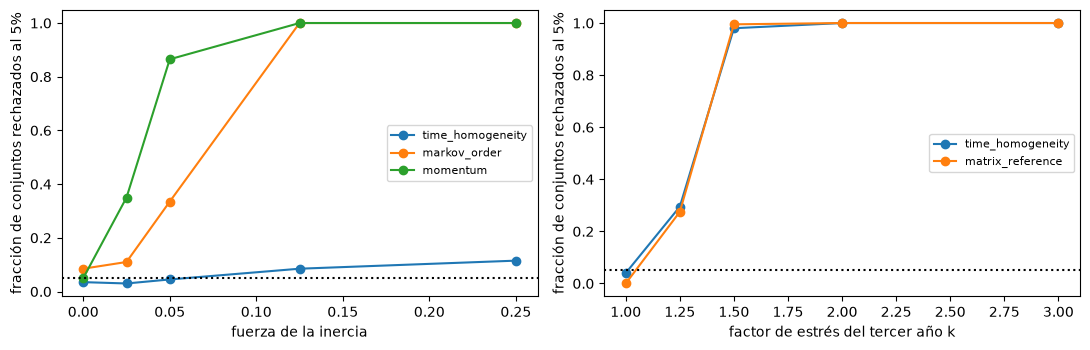

In [13]:
# Dibujar las curvas de potencia de las pruebas a lo largo de las dos escaleras
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
for t in ids_m:
    left.plot(strengths, rates_m[t], marker="o", label=t[7:])
for t in ids_c:
    right.plot(factors, rates_c[t], marker="o", label=t[7:])
left.set_xlabel("fuerza de la inercia")
right.set_xlabel("factor de estrés del tercer año k")
for ax in (left, right):
    ax.axhline(0.05, color="black", linestyle=":")
    ax.set_ylabel("fracción de conjuntos rechazados al 5%")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

El panel izquierdo es la respuesta a qué prueba ve la inercia: con fuerza 0,125 las pruebas de orden y de inercia rechazan el 100% de los conjuntos, y la de homogeneidad solo el 8,5%, frente a 3,5% cuando no hay ninguna. El panel derecho es la imagen en espejo: un tercer año estresado lo ve la homogeneidad (29,5% con k = 1,25 y 98% con k = 1,5) y la prueba de año contra agrupada, que una cadena de Markov con inercia no activaría. Con fuerza cero la prueba de orden rechaza el 8,5% de los conjuntos y la de inercia el 5%, cerca del nivel nominal. Las curvas son una propiedad de este diseño, cinco años y 7.113 deudores, y un portafolio más pequeño las desplazaría todas hacia la derecha.

### Paso 6: la cadena frente a la cohorte que la vivió

El sentido de una matriz es una proyección. El artefacto guarda, para cinco ventanas de cinco años, la cohorte fija del primer año de la ventana seguida hasta el final (`outputs.lifetime`) junto a lo que proyectan las matrices anuales de la ventana. Hay que distinguir tres números. **Vivido, incumplido (`cumulative_d2`)**: todo incumplido calificado, de la página de incumplimientos. **Vivido, en incumplimiento al final (`default_end`)**: calificaciones que siguen en una categoría de incumplimiento en la página de transiciones al final de la ventana, lo que pierde los incumplimientos retirados o recalificados dentro de la ventana. **Encadenado**: las cinco matrices anuales de la ventana multiplicadas, con los retiros como estado absorbente, de modo que una calificación que cayó en incumplimiento cuenta; por definición queda entre los otros dos. La matriz agrupada a la quinta y el generador EM proyectan el mismo horizonte sin las matrices de la ventana.

La celda siguiente encadena con el motor las cinco matrices anuales de la ventana 2020 a 2024, una vez con las retiradas como estado y otra con ellas quitadas, eleva la matriz agrupada a la quinta potencia, toma la proyección EM a cinco años, y los pone junto a lo que vivió la cohorte.

In [14]:
# Encadenar las cinco matrices anuales, proyectar con la matriz agrupada y EM, leer lo vivido por la cohorte
window = out["lifetime"][-1]
span = [c for c in cohorts if int(window["first"]) <= int(c["label"]) <= int(window["last"])]
chain_state, chain_exclude = np.eye(9), np.eye(8)
for c in span:
    table = np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))])
    gone_c = np.append(np.array(c["withdrawn"], dtype=float), 0.0)
    chain_state = chain_state @ estimators.cohort(table, gone_c, treatment="state")["matrix"]
    chain_exclude = chain_exclude @ estimators.cohort(table, gone_c, treatment="exclude")["matrix"]
em = em_generator([{"counts": t, "dt": 1.0} for t in annual])
rows = (
    ("vivido: todo incumplido", np.array(window["observed"]["cumulative_d2"])),
    ("vivido: en incumplimiento al final", np.array(window["observed"]["default_end"])),
    ("encadenado, retiradas como estado", chain_state[:7, 7]),
    ("encadenado, retiradas quitadas", chain_exclude[:7, 7]),
    ("matriz agrupada a la quinta potencia", np.linalg.matrix_power(P, 5)[:7, 7]),
    ("generador EM, cinco años", expm(5 * em["generator"])[:7, 7]),
)
withdrawn_end = np.array(window["observed"]["withdrawn_end"])

print("ventana:", window["label"], "| tamaños de cohorte, B y CCC-C:", window["size"][5], window["size"][6])
print(f"{'':58s}{'B':>10s}{'CCC-C':>10s}")
for label, values in rows:
    print(f"{label:58s}{values[5]:10.4f}{values[6]:10.4f}")
print(f"{'fracción retirada al final':58s}{withdrawn_end[5]:10.4f}{withdrawn_end[6]:10.4f}")

ventana: 2020-2024 | tamaños de cohorte, B y CCC-C: 1846 238
                                                                   B     CCC-C
vivido: todo incumplido                                       0.1126    0.6144
vivido: en incumplimiento al final                            0.0060    0.0000
encadenado, retiradas como estado                             0.0259    0.0910
encadenado, retiradas quitadas                                0.0440    0.2047
matriz agrupada a la quinta potencia                          0.0821    0.2530
generador EM, cinco años                                      0.0821    0.2527
fracción retirada al final                                    0.5531    0.8109


La celda siguiente dibuja las seis lecturas para B y CCC-C lado a lado.

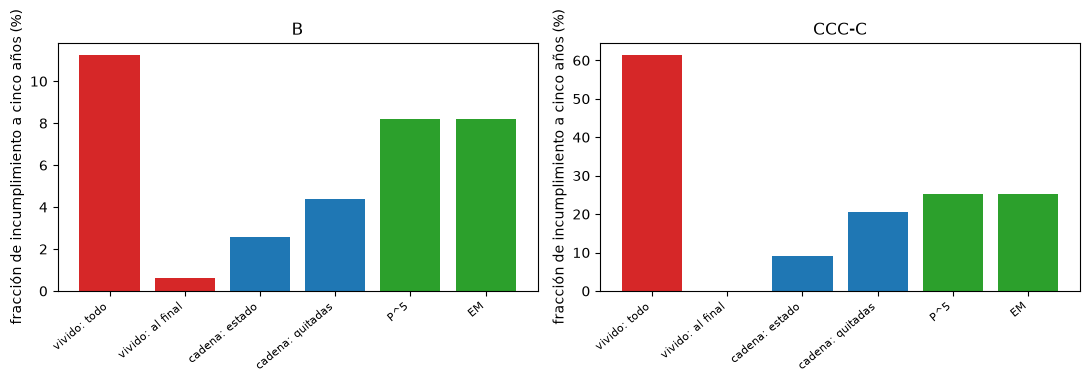

In [15]:
# Dibujar la fracción de incumplimiento a cinco años de B y CCC-C bajo cada lectura
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
names = ["vivido: todo", "vivido: al final", "cadena: estado",
         "cadena: quitadas", "P^5", "EM"]
for ax, g in zip(axes, (5, 6)):
    colors = ["tab:red", "tab:red", "tab:blue", "tab:blue", "tab:green", "tab:green"]
    ax.bar(names, [100 * v[g] for _, v in rows], color=colors)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, rotation=40, ha="right", fontsize=8)
    ax.set_ylabel("fracción de incumplimiento a cinco años (%)")
    ax.set_title(grades[g])
fig.tight_layout()
plt.show()

Tres números distintos se esconden tras "la frecuencia de incumplimiento de la cohorte". Contando todo deudor calificado que cayó en incumplimiento, el 61,4% de la cohorte CCC-C de 2020 cayó en incumplimiento dentro de la ventana, y sin embargo ninguno sigue en incumplimiento al final, y el 81,1% se retiró. Encadenar las matrices anuales con las retiradas como estado da 9,1%, entre las dos lecturas vividas como exige su definición, y quitar las retiradas da 20,5%. La matriz agrupada a la quinta potencia da 25,3%, una proyección que nunca vio la ventana. La figura muestra que con cuatro quintos de la cohorte salidos por retiro, la comparación no puede separar una falla de la cadena de Markov de la manera en que se cuentan las retiradas.

## Resultados

**Respuesta:** ninguna matriz sola describe a las cohortes, y la prueba que lo dice no es la que encuentra la inercia. El estadístico anual de homogeneidad es 12028,16 con 1075 grados de libertad, 11,2 veces sus grados de libertad, y cada uno de los 26 años rechaza la matriz agrupada. Pero en un conjunto de datos con semilla e inercia plantada la prueba de orden (p = 2e-13) y la prueba de inercia (c ajustado = 0,35) rechazan mientras la de homogeneidad no (p = 0,43); en 200 conjuntos con fuerza 0,125 la homogeneidad rechaza el 8,5% frente al 100% de las pruebas de orden y de inercia, mientras que un tercer año estresado es el caso que la homogeneidad ve (29,5% con k = 1,25, 98% con k = 1,5).

- **Las pruebas de estabilidad del BCE.** El ancho de banda ponderado de la matriz es descriptivo y no lleva luz; las pruebas z de migración, ajustadas por Holm entre celdas, señalan 2 de las 26 cohortes al 5%.
- **Movilidad.** La matriz agrupada tiene M_SVD 0,135 e índice de traza 0,137; el año más móvil es 2002 (0,219) y el menos móvil 2023 (0,066), y M_SVD se correlaciona 0,27 con la tasa de incumplimiento de los grados especulativos.
- **Encadenado frente a vivido.** En la ventana 2020 a 2024 el 61,4% de la cohorte CCC-C cayó en incumplimiento (todo deudor calificado) mientras ninguno seguía en incumplimiento al final y el 81,1% se había retirado; las matrices anuales encadenadas dan 9,1% y la matriz agrupada a la quinta potencia 25,3%. Para B las lecturas son 11,3% vivido, 2,6% encadenado y 8,2% con la potencia agrupada.

Lo que este notebook no muestra: cómo llevar una curva de PD a un año nuevo (notebook 05), ni qué cuesta una PD en capital (notebook 07).

## Resumen

- La homogeneidad en el tiempo, la prueba de año contra agrupada, la prueba de orden y la prueba de inercia hacen preguntas distintas; el rechazo de una no nombra el desvío, y que una pase no despeja a la cadena de las otras.
- El ancho de banda ponderado de la matriz del BCE es descriptivo y sus pruebas z de migración, ajustadas entre celdas, señalan pocas cohortes aquí; los índices de movilidad se mueven con el ciclo pero no son la tasa de incumplimiento.
- Los conteos de calificaciones bastan para la homogeneidad y las pruebas del BCE; el orden y la inercia necesitan trayectorias, así que corren sobre trayectorias simuladas de verdad conocida.
- Una proyección se compara con lo que vivió una cohorte solo después de decir cuál de los tres números de incumplimiento cuenta cada una.

**Qué probar después.** Cambia la fuerza de inercia del sorteo del Paso 5 a 0,05 y vuelve a correrlo con otras semillas; luego lee el notebook 05.

## Referencias

- ESMA, publicación CEREP de calificaciones y transiciones de agencias calificadoras. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. y Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), ecuaciones 3.1, 3.5, 3.8 y 3.12. https://doi.org/10.1214/aoms/1177707039
- BCE (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sección 2.5.5 (ancho de banda ponderado de la matriz y pruebas z de migración). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Jafry, Y. y Schuermann, T. (2004), Measurement, estimation and comparison of credit migration matrices, Journal of Banking and Finance 28(11), para los índices de movilidad.
- dos Reis, G., Pfeuffer, M. y Smith, G. (2020), Capturing model risk and rating inercia in the estimation of probabilities of default and credit rating migrations, Quantitative Finance, arXiv 1809.09889.
- Holm, S. (1979), A simple sequentially rejective multiple test procedure, Scandinavian Journal of Statistics 6(2), para el ajuste entre celdas.